Перші 10 результатів:
 Реальні значення  Передбачені значення
            219.0                145.81
             70.0                188.86
            202.0                147.96
            230.0                203.93
            111.0                131.81
             84.0                127.51
            242.0                322.32
            272.0                197.47
             94.0                 61.86
             96.0                167.33


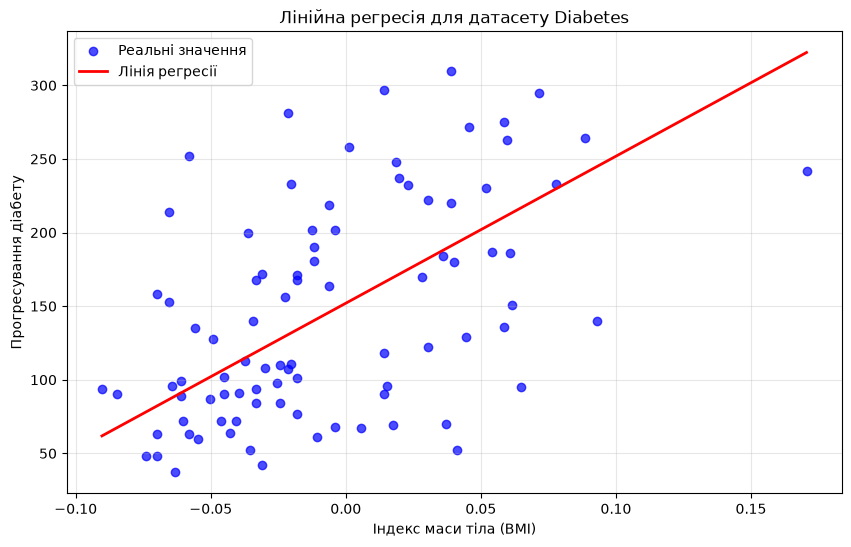

Метрики якості моделі:
Метрика  Значення
    MAE   52.2600
    MSE 4061.8259
     R²    0.2334


In [3]:
import pandas as pd
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt 
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

diabetes = load_diabetes()

X = diabetes.data[:, [2]]

y = diabetes.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

results = pd.DataFrame({
    'Реальні значення': y_test[:10],
    'Передбачені значення': y_pred[:10]
})

print("Перші 10 результатів:")
print(results.round(2).to_string(index=False))

plt.figure(figsize=(10, 6))

plt.scatter(
    X_test[:, 0],
    y_test,
    color='blue',
    label='Реальні значення',
    alpha=0.7
)

X_line = np.linspace(
    X_test.min(),
    X_test.max(),
    100
).reshape(-1, 1)

y_line = model.predict(X_line)

plt.plot(
    X_line[:, 0],
    y_line,
    color='red',
    linewidth=2,
    label='Лінія регресії'
)

plt.xlabel('Індекс маси тіла (BMI)')
plt.ylabel('Прогресування діабету')
plt.title('Лінійна регресія для датасету Diabetes')
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

metrics = pd.DataFrame({
'Метрика': ['MAE', 'MSE', 'R²'],
'Значення': [mae, mse, r2]
})

print("Метрики якості моделі:")
print(metrics.round(4).to_string(index=False))